# Pemodelan Klasifikasi Risiko PM2.5

## 1. Tujuan Pemodelan

Pemodelan ini bertujuan memprediksi kategori risiko kualitas udara pada hari berikutnya untuk setiap kabupaten/kota di Pulau Jawa.

Kategori risiko ditentukan berdasarkan nilai target PM2.5:

- Baik (Aman): PM2.5 ≤ 15 µg/m³
- Sedang (Waspada): 15 < PM2.5 ≤ 55 µg/m³
- Tidak Sehat (Bahaya): PM2.5 > 55 µg/m³

## 2. Rumusan Masalah

Berdasarkan kondisi kualitas udara dan histori beberapa hari sebelumnya, apakah kondisi PM2.5 pada hari berikutnya dapat diklasifikasikan ke dalam kategori Baik, Sedang, atau Tidak Sehat?

## 3. Unit Analisis

Satu baris data merepresentasikan satu kabupaten/kota pada satu tanggal.

Contoh:

- Wilayah: Kota Bekasi
- Tanggal: 2025-01-01
- Fitur: kondisi PM2.5 dan polutan pada tanggal tersebut serta histori sebelumnya
- Target: kategori risiko PM2.5 pada tanggal berikutnya

## 4. Jenis Masalah

Masalah ini merupakan klasifikasi multiclass dengan tiga kelas:

1. Baik (Aman)
2. Sedang (Waspada)
3. Tidak Sehat (Bahaya)

Model klasifikasi akan digunakan sebagai pendekatan langsung untuk memprediksi kategori risiko.

Sebagai pembanding, pendekatan regresi forecasting juga dapat digunakan dengan cara:

1. Memprediksi nilai PM2.5 hari berikutnya.
2. Mengubah nilai prediksi tersebut menjadi kategori risiko.

## 5. Tujuan Evaluasi

Evaluasi tidak hanya berfokus pada accuracy karena distribusi kelas tidak seimbang. Metrik utama yang digunakan adalah:

- Precision setiap kelas
- Recall setiap kelas
- F1-score setiap kelas
- Macro F1-score
- Balanced accuracy
- Confusion matrix

Perhatian khusus diberikan pada recall kelas Baik dan Tidak Sehat karena kedua kelas tersebut lebih sedikit dibandingkan kelas Sedang.


# Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

# Membaca Dataset

In [2]:
path_data = Path("../../data/data_gabungan/airguard_preprocessed.csv")

df = pd.read_csv(
    path_data,
    parse_dates=["tanggal"]
)

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


# Pemeriksaan ukuran dan periode

In [3]:
print("Ukuran dataset:", df.shape)
print("Periode:", df["tanggal"].min().date(), "sampai", df["tanggal"].max().date())
print("Jumlah kabupaten/kota:", df["nama_kabkota"].nunique())
print("Jumlah provinsi:", df["provinsi"].nunique())

Ukuran dataset: (181594, 26)
Periode: 2022-08-18 sampai 2026-10-21
Jumlah kabupaten/kota: 119
Jumlah provinsi: 6


# Melihat struktur kolom

In [4]:
display(df.head())

print("Daftar kolom:")
print(df.columns.tolist())

print("\nTipe data:")
display(df.dtypes)

,kode_kabkota,nama_kabkota,provinsi,tipe,latitude,longitude,elevasi_m,luas_km2,penduduk,tanggal,pm10,pm2_5,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,pm2_5_lag_1,pm2_5_lag_2,pm2_5_lag_3,pm2_5_lag_7,pm2_5_lag_14,pm2_5_rolling_3,pm2_5_rolling_7,pm2_5_rolling_14,target_pm2_5,kategori_target_pm2_5
0,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-18,36.625000,22.025000,355.333333,5.283333,4.895833,112.125000,22.691667,16.329167,15.075000,18.687500,25.705882,20.348611,19.065476,20.370238,21.333333,Sedang (Waspada)
1,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-19,35.900000,21.333333,306.250000,3.875000,4.629167,118.750000,22.025000,22.691667,16.329167,17.145833,9.258333,22.016667,19.663690,21.232738,23.479167,Sedang (Waspada)
2,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-20,39.495833,23.479167,289.708333,3.608333,4.645833,111.375000,21.333333,22.025000,22.691667,22.412500,21.075000,22.279167,19.816071,21.404464,27.037500,Sedang (Waspada)
3,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-21,44.529167,27.037500,477.708333,9.495833,9.620833,129.208333,23.479167,21.333333,22.025000,17.779167,27.645833,23.950000,21.138690,21.361012,18.487500,Sedang (Waspada)
4,31.01,Kabupaten Administrasi Kepulauan Seribu,DKI Jakarta,Kabupaten,-5.746481,106.61316,8.0,10.951,30334.0,2022-08-22,31.383333,18.487500,350.500000,2.020833,5.220833,128.666667,27.037500,23.479167,21.333333,15.075000,36.504167,23.001389,21.626190,20.074107,27.937500,Sedang (Waspada)


Daftar kolom:
['kode_kabkota', 'nama_kabkota', 'provinsi', 'tipe', 'latitude', 'longitude', 'elevasi_m', 'luas_km2', 'penduduk', 'tanggal', 'pm10', 'pm2_5', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'pm2_5_lag_1', 'pm2_5_lag_2', 'pm2_5_lag_3', 'pm2_5_lag_7', 'pm2_5_lag_14', 'pm2_5_rolling_3', 'pm2_5_rolling_7', 'pm2_5_rolling_14', 'target_pm2_5', 'kategori_target_pm2_5']

Tipe data:


kode_kabkota                    float64
nama_kabkota                     object
provinsi                         object
tipe                             object
latitude                        float64
longitude                       float64
elevasi_m                       float64
luas_km2                        float64
penduduk                        float64
tanggal                  datetime64[ns]
pm10                            float64
pm2_5                           float64
carbon_monoxide                 float64
nitrogen_dioxide                float64
sulphur_dioxide                 float64
ozone                           float64
pm2_5_lag_1                     float64
pm2_5_lag_2                     float64
pm2_5_lag_3                     float64
pm2_5_lag_7                     float64
pm2_5_lag_14                    float64
pm2_5_rolling_3                 float64
pm2_5_rolling_7                 float64
pm2_5_rolling_14                float64
target_pm2_5                    float64


# Cek missing value

In [5]:
missing_check = pd.DataFrame({
    "jumlah_missing": df.isna().sum(),
    "persentase_missing": df.isna().mean() * 100
})

missing_check = missing_check.sort_values(
    "jumlah_missing",
    ascending=False
)

display(missing_check)

,jumlah_missing,persentase_missing
kode_kabkota,0,0.0
nama_kabkota,0,0.0
target_pm2_5,0,0.0
pm2_5_rolling_14,0,0.0
pm2_5_rolling_7,0,0.0
pm2_5_rolling_3,0,0.0
pm2_5_lag_14,0,0.0
pm2_5_lag_7,0,0.0
pm2_5_lag_3,0,0.0
pm2_5_lag_2,0,0.0


# Memeriksa duplikasi wilayah dan tanggal

In [6]:
jumlah_duplikat = df.duplicated(
    subset=["nama_kabkota", "tanggal"]
).sum()

print("Jumlah duplikasi wilayah-tanggal:", jumlah_duplikat)

Jumlah duplikasi wilayah-tanggal: 0


# Memeriksa distribusi target

In [8]:
distribusi_target = (
    df[target]
    .value_counts()
    .rename_axis("kategori")
    .reset_index(name="jumlah")
)

distribusi_target["persentase"] = (
    distribusi_target["jumlah"]
    / distribusi_target["jumlah"].sum()
    * 100
)

distribusi_target["persentase"] = (
    distribusi_target["persentase"]
    .round(2)
)

display(distribusi_target)

,kategori,jumlah,persentase
0,Sedang (Waspada),118774,65.41
1,Tidak Sehat (Bahaya),35858,19.75
2,Baik (Aman),26962,14.85


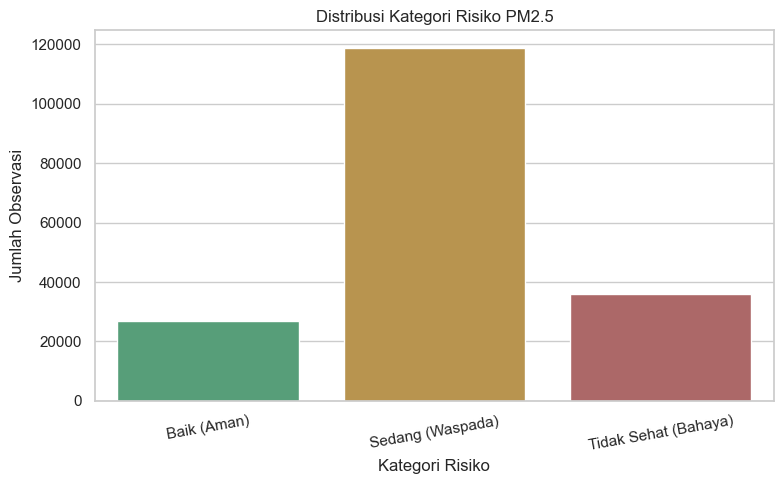

In [9]:
urutan_kategori = [
    "Baik (Aman)",
    "Sedang (Waspada)",
    "Tidak Sehat (Bahaya)"
]

warna_kategori = {
    "Baik (Aman)": "#4BAA78",
    "Sedang (Waspada)": "#C99A3E",
    "Tidak Sehat (Bahaya)": "#B85C5C"
}

plt.figure(figsize=(8, 5))

sns.barplot(
    data=distribusi_target,
    x="kategori",
    y="jumlah",
    order=urutan_kategori,
    hue="kategori",
    palette=warna_kategori,
    legend=False
)

plt.title("Distribusi Kategori Risiko PM2.5")
plt.xlabel("Kategori Risiko")
plt.ylabel("Jumlah Observasi")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

# Memeriksa distribusi target per periode

In [10]:
distribusi_tahunan = pd.crosstab(
    df["tanggal"].dt.year,
    df[target],
    normalize="index"
) * 100

distribusi_tahunan = distribusi_tahunan.reindex(
    columns=urutan_kategori
)

display(distribusi_tahunan.round(2))

kategori_target_pm2_5,Baik (Aman),Sedang (Waspada),Tidak Sehat (Bahaya)
tanggal,,,
2022,29.20,63.95,6.85
2023,21.52,69.68,8.80
2024,20.83,65.92,13.25
2025,4.94,61.78,33.28
2026,4.77,64.64,30.59


# Menentukan Target

In [11]:
target = "kategori_target_pm2_5"

y = df[target].copy()

print("Nama target:", target)
print("Jumlah kelas:", y.nunique())
print("Kelas:", y.unique())

Nama target: kategori_target_pm2_5
Jumlah kelas: 3
Kelas: ['Sedang (Waspada)' 'Baik (Aman)' 'Tidak Sehat (Bahaya)']


# Menentukan fitur

In [12]:
fitur_model = [
    # Variabel geografis
    "latitude",
    "longitude",
    "elevasi_m",
    "luas_km2",
    "penduduk",

    # Variabel kualitas udara saat ini
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone",

    # Fitur lag
    "pm2_5_lag_1",
    "pm2_5_lag_2",
    "pm2_5_lag_3",
    "pm2_5_lag_7",
    "pm2_5_lag_14",

    # Fitur rolling
    "pm2_5_rolling_3",
    "pm2_5_rolling_7",
    "pm2_5_rolling_14",

    # Fitur kalender
    "tahun",
    "bulan",
    "hari_dalam_minggu",
    "hari_dalam_tahun",
    "akhir_pekan"
]

# Memastikan semua fitur tersedia

In [13]:
kolom_tidak_tersedia = [
    kolom for kolom in fitur_model
    if kolom not in df.columns
]

if kolom_tidak_tersedia:
    print("Kolom berikut belum tersedia:")
    print(kolom_tidak_tersedia)
else:
    print("Semua fitur tersedia.")

Kolom berikut belum tersedia:
['tahun', 'bulan', 'hari_dalam_minggu', 'hari_dalam_tahun', 'akhir_pekan']


In [15]:
# Pastikan tanggal bertipe datetime
df["tanggal"] = pd.to_datetime(df["tanggal"])

# Feature engineering kalender
df["tahun"] = df["tanggal"].dt.year
df["bulan"] = df["tanggal"].dt.month
df["hari_dalam_minggu"] = df["tanggal"].dt.dayofweek
df["hari_dalam_tahun"] = df["tanggal"].dt.dayofyear
df["akhir_pekan"] = (
    df["hari_dalam_minggu"] >= 5
).astype(int)

print("Fitur kalender berhasil dibuat.")

Fitur kalender berhasil dibuat.


In [19]:
fitur_kalender = [
    "tahun",
    "bulan",
    "hari_dalam_minggu",
    "hari_dalam_tahun",
    "akhir_pekan"
]

display(df[fitur_kalender].head())

,tahun,bulan,hari_dalam_minggu,hari_dalam_tahun,akhir_pekan
0,2022,8,3,230,0
1,2022,8,4,231,0
2,2022,8,5,232,1
3,2022,8,6,233,1
4,2022,8,0,234,0


# Split x dan y

In [16]:
X = df[fitur_model].copy()
y = df[target].copy()

print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)

Ukuran X: (181594, 24)
Ukuran y: (181594,)


# Memeriksa fitur yang digunakan 

In [20]:
display(X.head())
display(y.head())

,latitude,longitude,elevasi_m,luas_km2,penduduk,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,pm2_5_lag_1,pm2_5_lag_2,pm2_5_lag_3,pm2_5_lag_7,pm2_5_lag_14,pm2_5_rolling_3,pm2_5_rolling_7,pm2_5_rolling_14,tahun,bulan,hari_dalam_minggu,hari_dalam_tahun,akhir_pekan
0,-5.746481,106.61316,8.0,10.951,30334.0,22.025000,36.625000,355.333333,5.283333,4.895833,112.125000,22.691667,16.329167,15.075000,18.687500,25.705882,20.348611,19.065476,20.370238,2022,8,3,230,0
1,-5.746481,106.61316,8.0,10.951,30334.0,21.333333,35.900000,306.250000,3.875000,4.629167,118.750000,22.025000,22.691667,16.329167,17.145833,9.258333,22.016667,19.663690,21.232738,2022,8,4,231,0
2,-5.746481,106.61316,8.0,10.951,30334.0,23.479167,39.495833,289.708333,3.608333,4.645833,111.375000,21.333333,22.025000,22.691667,22.412500,21.075000,22.279167,19.816071,21.404464,2022,8,5,232,1
3,-5.746481,106.61316,8.0,10.951,30334.0,27.037500,44.529167,477.708333,9.495833,9.620833,129.208333,23.479167,21.333333,22.025000,17.779167,27.645833,23.950000,21.138690,21.361012,2022,8,6,233,1
4,-5.746481,106.61316,8.0,10.951,30334.0,18.487500,31.383333,350.500000,2.020833,5.220833,128.666667,27.037500,23.479167,21.333333,15.075000,36.504167,23.001389,21.626190,20.074107,2022,8,0,234,0


0    Sedang (Waspada)
1    Sedang (Waspada)
2    Sedang (Waspada)
3    Sedang (Waspada)
4    Sedang (Waspada)
Name: kategori_target_pm2_5, dtype: object

# Menentukan periode split

In [21]:
# Pastikan data terurut berdasarkan tanggal dan wilayah
df = df.sort_values(
    ["tanggal", "nama_kabkota"]
).reset_index(drop=True)

tanggal_train_awal = pd.Timestamp("2022-08-18")
tanggal_train_akhir = pd.Timestamp("2024-12-31")

tanggal_val_awal = pd.Timestamp("2025-01-01")
tanggal_val_akhir = pd.Timestamp("2025-12-31")

tanggal_test_awal = pd.Timestamp("2026-01-01")
tanggal_test_akhir = pd.Timestamp("2026-10-21")

# Membuat mask split

In [22]:
mask_train = (
    (df["tanggal"] >= tanggal_train_awal) &
    (df["tanggal"] <= tanggal_train_akhir)
)

mask_val = (
    (df["tanggal"] >= tanggal_val_awal) &
    (df["tanggal"] <= tanggal_val_akhir)
)

mask_test = (
    (df["tanggal"] >= tanggal_test_awal) &
    (df["tanggal"] <= tanggal_test_akhir)
)

# Membagi x dan y 

In [23]:
X_train = X.loc[mask_train].copy()
y_train = y.loc[mask_train].copy()

X_val = X.loc[mask_val].copy()
y_val = y.loc[mask_val].copy()

X_test = X.loc[mask_test].copy()
y_test = y.loc[mask_test].copy()

# Memeriksa ukuran data

In [24]:
print("Ukuran data train:", X_train.shape, y_train.shape)
print("Ukuran data validation:", X_val.shape, y_val.shape)
print("Ukuran data test:", X_test.shape, y_test.shape)

Ukuran data train: (103173, 24) (103173,)
Ukuran data validation: (43435, 24) (43435,)
Ukuran data test: (34986, 24) (34986,)


# Memeriksa periode setiap subset

In [25]:
def cek_periode(nama, mask):
    data_subset = df.loc[mask]

    print(f"{nama}")
    print("Tanggal awal :", data_subset["tanggal"].min().date())
    print("Tanggal akhir:", data_subset["tanggal"].max().date())
    print("Jumlah baris :", len(data_subset))
    print()

cek_periode("TRAIN", mask_train)
cek_periode("VALIDATION", mask_val)
cek_periode("TEST", mask_test)

TRAIN
Tanggal awal : 2022-08-18
Tanggal akhir: 2024-12-31
Jumlah baris : 103173

VALIDATION
Tanggal awal : 2025-01-01
Tanggal akhir: 2025-12-31
Jumlah baris : 43435

TEST
Tanggal awal : 2026-01-01
Tanggal akhir: 2026-10-21
Jumlah baris : 34986



# Memeriksa distribusi kelas

In [26]:
def distribusi_kelas(nama, data_target):
    hasil = (
        data_target
        .value_counts()
        .reindex(urutan_kategori, fill_value=0)
        .rename_axis("kategori")
        .reset_index(name="jumlah")
    )

    hasil["persentase"] = (
        hasil["jumlah"]
        / hasil["jumlah"].sum()
        * 100
    ).round(2)

    hasil.insert(0, "subset", nama)

    return hasil

distribusi_split = pd.concat([
    distribusi_kelas("Train", y_train),
    distribusi_kelas("Validation", y_val),
    distribusi_kelas("Test", y_test)
], ignore_index=True)

display(distribusi_split)

,subset,kategori,jumlah,persentase
0,Train,Baik (Aman),10068,9.76
1,Train,Sedang (Waspada),68590,66.48
2,Train,Tidak Sehat (Bahaya),24515,23.76
3,Validation,Baik (Aman),10556,24.30
4,Validation,Sedang (Waspada),28604,65.85
5,Validation,Tidak Sehat (Bahaya),4275,9.84
6,Test,Baik (Aman),6338,18.12
7,Test,Sedang (Waspada),21580,61.68
8,Test,Tidak Sehat (Bahaya),7068,20.20


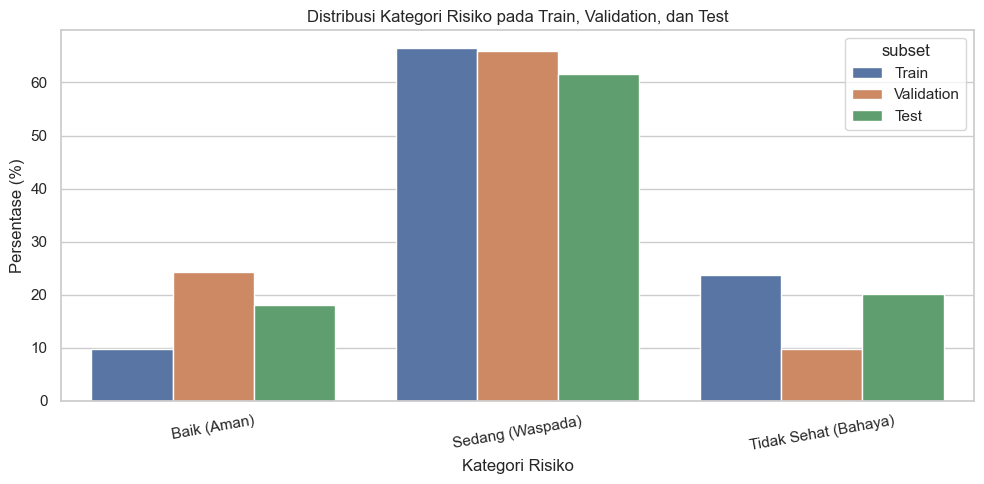

In [27]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=distribusi_split,
    x="kategori",
    y="persentase",
    hue="subset"
)

plt.title("Distribusi Kategori Risiko pada Train, Validation, dan Test")
plt.xlabel("Kategori Risiko")
plt.ylabel("Persentase (%)")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()